# Portfölj 1: Tangency Portfolio

* Namn: Albin Viklund
* Datum: 2026-10-19

### Importera biblotek

In [67]:
import numpy as np
import pandas as pd
pd.options.display.max_columns = 50
pd.options.display.max_rows = 50
import openpyxl # Detta bibliotek används för att importera och exportera Excelfiler

import jinja2 # Detta bibliotek är valfritt, men är till för att färglägga DataFrames

# Bibliotek för datavisualisering (inbyggda i Riskfolio-Lib men behöver importeras för att fungera)
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'retina' # Denna rad förbättrar skärpan i plt-grafer.
#plt.rcParams['figure.dpi'] = 300 # Denna rad göra i princip samma som raden ovan, men jag tycker retina är snyggare

# Nya bibliotek
import yfinance as yf # Hämta aktiedata från Yahoo Finance
import riskfolio as rp # Portföljoptimering
import warnings 
warnings.filterwarnings("ignore") # Vi använder denna inställning för att ignorera varningar (finns en del i Riskfolio-Lib)

In [68]:
print("Yfinance: ", yf.__version__)
print("Riskfolio-Lib: ", rp.__version__)
print("Pandas: ", pd.__version__)
print("Numpy: ", np.__version__)
print("Matplotlib: ", matplotlib.__version__)
print("Seaborn: ", sns.__version__)
print("")
print("openpyxl: ", openpyxl.__version__)
print("jinja2: ", jinja2.__version__)

Yfinance:  0.2.65
Riskfolio-Lib:  7.4.0
Pandas:  3.0.6
Numpy:  2.4.6
Matplotlib:  3.10.5
Seaborn:  0.13.2

openpyxl:  3.1.5
jinja2:  3.1.6


### 1.Ladda ner aktier

#### Ladda ner stängningspriser

In [69]:
# Definiera start och slutdatum för tidsserien
start_date = "2021-01-01"
end_date = "2025-12-31"

# Importera dina aktiesymboler från Excel-filen
asset_classes = pd.read_excel("asset_classes.xlsx").sort_values(by = ["Assets"])
assets = list(asset_classes["Assets"])

# Ladda ner stängningskurser för alla valda aktier med yfinance
data = yf.download(assets, start=start_date, end=end_date)["Close"].ffill()
data

[*********************100%***********************]  12 of 12 completed


Ticker,ALFA.ST,AXFO.ST,CLAS-B.ST,EVO.ST,FOI-B.ST,HUSQ-A.ST,KINV-B.ST,NIBE-B.ST,SEB-A.ST,SHB-A.ST,SKIS-B.ST,THULE.ST
Date,,,,,,,,,,,,
2021-01-04,204.914642,159.840378,58.209118,808.360168,918.973389,88.067261,259.096069,65.973602,56.899403,45.606937,98.099716,246.590424
2021-01-05,205.004150,158.198456,58.283306,833.912415,915.525085,89.296112,258.411163,64.703964,56.481525,45.308918,96.272911,249.305420
2021-01-07,207.958389,161.153900,57.801010,804.002441,965.525513,86.838425,252.902283,68.369156,59.217979,47.361897,97.003632,244.035034
2021-01-08,208.137421,161.564346,58.542999,802.813904,970.698059,89.705734,255.909836,69.135735,57.910412,46.688614,99.013123,247.229172
2021-01-11,206.705048,161.071808,57.652615,802.219727,958.628967,87.657654,250.996506,67.961906,57.195969,46.567196,97.003632,252.180176
...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-19,453.035400,278.914215,287.105835,624.799988,466.271729,43.764999,81.260002,34.683685,180.865189,115.747215,167.699997,224.854736
2025-12-22,453.920624,277.752075,290.996155,621.799988,473.157593,43.813358,82.040001,34.485435,180.724442,115.659882,167.100006,226.393509
2025-12-23,453.822266,278.236298,293.135834,621.200012,473.157593,43.813358,82.080002,34.505260,180.865189,116.489456,167.000000,225.239426


#### Beräkna daglig avkastning i proccent

In [70]:
# Beräkna procentuell daglig avkastning
returns = data.pct_change().dropna()
returns

Ticker,ALFA.ST,AXFO.ST,CLAS-B.ST,EVO.ST,FOI-B.ST,HUSQ-A.ST,KINV-B.ST,NIBE-B.ST,SEB-A.ST,SHB-A.ST,SKIS-B.ST,THULE.ST
Date,,,,,,,,,,,,
2021-01-05,0.000437,-0.010272,0.001275,0.031610,-0.003752,0.013954,-0.002643,-0.019245,-0.007344,-0.006535,-0.018622,0.011010
2021-01-07,0.014411,0.018682,-0.008275,-0.035867,0.054614,-0.027523,-0.021318,0.056646,0.048449,0.045311,0.007590,-0.021140
2021-01-08,0.000861,0.002547,0.012837,-0.001478,0.005357,0.033019,0.011892,0.011212,-0.022081,-0.014216,0.020716,0.013089
2021-01-11,-0.006882,-0.003049,-0.015209,-0.000740,-0.012433,-0.022831,-0.019199,-0.016979,-0.012337,-0.002601,-0.020295,0.020026
2021-01-12,0.019922,0.000510,0.003861,0.012346,0.025180,0.009346,-0.001186,-0.013394,0.025689,0.020384,0.000000,0.002533
...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-19,0.008539,0.011947,0.008197,0.001282,0.009585,-0.014161,-0.007330,-0.003985,0.010220,0.010290,-0.014689,0.002573
2025-12-22,0.001954,-0.004167,0.013550,-0.004802,0.014768,0.001105,0.009599,-0.005716,-0.000778,-0.000755,-0.003578,0.006843
2025-12-23,-0.000217,0.001743,0.007353,-0.000965,0.000000,0.000000,0.000488,0.000575,0.000779,0.007173,-0.000598,-0.005098


#### Ladda ner jämförelse index

In [71]:
# Ladda ner jämförelseindex (OMXS30) och räkna ut dess dagliga avkastning
benchmark = yf.download("^OMX", start=start_date, end=end_date)["Close"]
benchmark_returns = benchmark.pct_change().dropna()

[*********************100%***********************]  1 of 1 completed


### 2.Initial analys av aktier och index

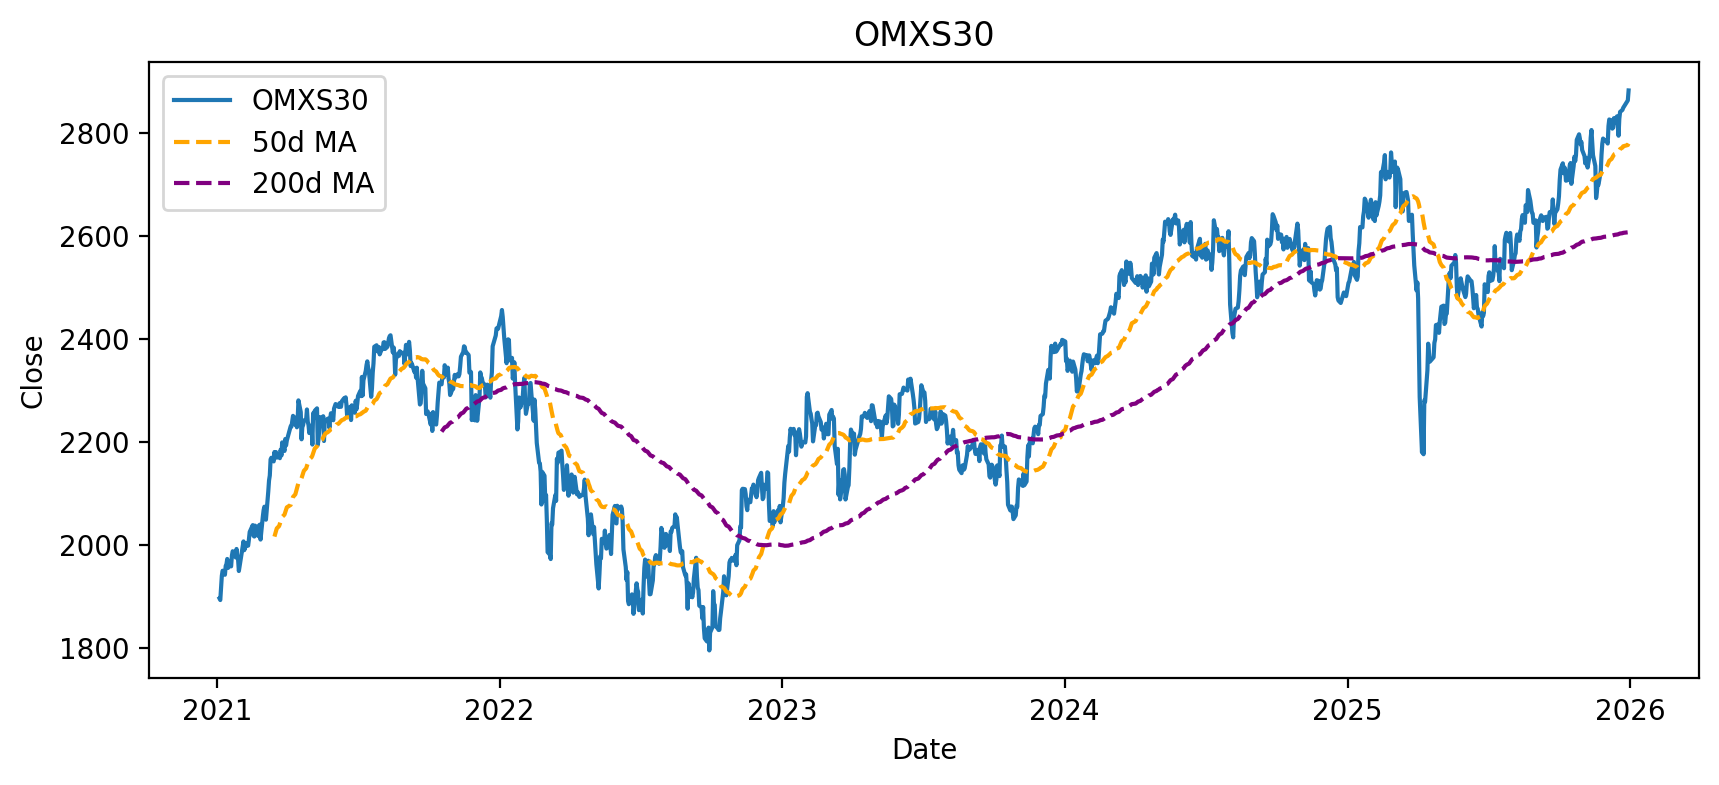

In [72]:
# Visualisera jämförelseindex för att få en känsla av hur marknaden har rört sig över tidsperioden
plt.figure(figsize=(10, 4)) 

plt.plot(benchmark.index,        # X-axel: datum
         benchmark,              # Y-axel: OMXS30-pris
         label="OMXS30")         # Namn som visas i legenden


plt.plot(benchmark.index, 
         benchmark.rolling(window=50).mean(),  # Rullande medelvärde
         label='50d MA', 
         color="orange",        
         linestyle='--')        


plt.plot(benchmark.index, 
         benchmark.rolling(window=200).mean(), 
         label='200d MA', 
         color="purple",        
         linestyle='--')        

plt.title("OMXS30")             # Diagramrubrik
plt.xlabel("Date")              # X-axel rubrik
plt.ylabel("Close")             # Y-axel rubrik
plt.legend(loc=2)               # Placera legend i övre vänstra hörnet
plt.show()                      # Visa grafen

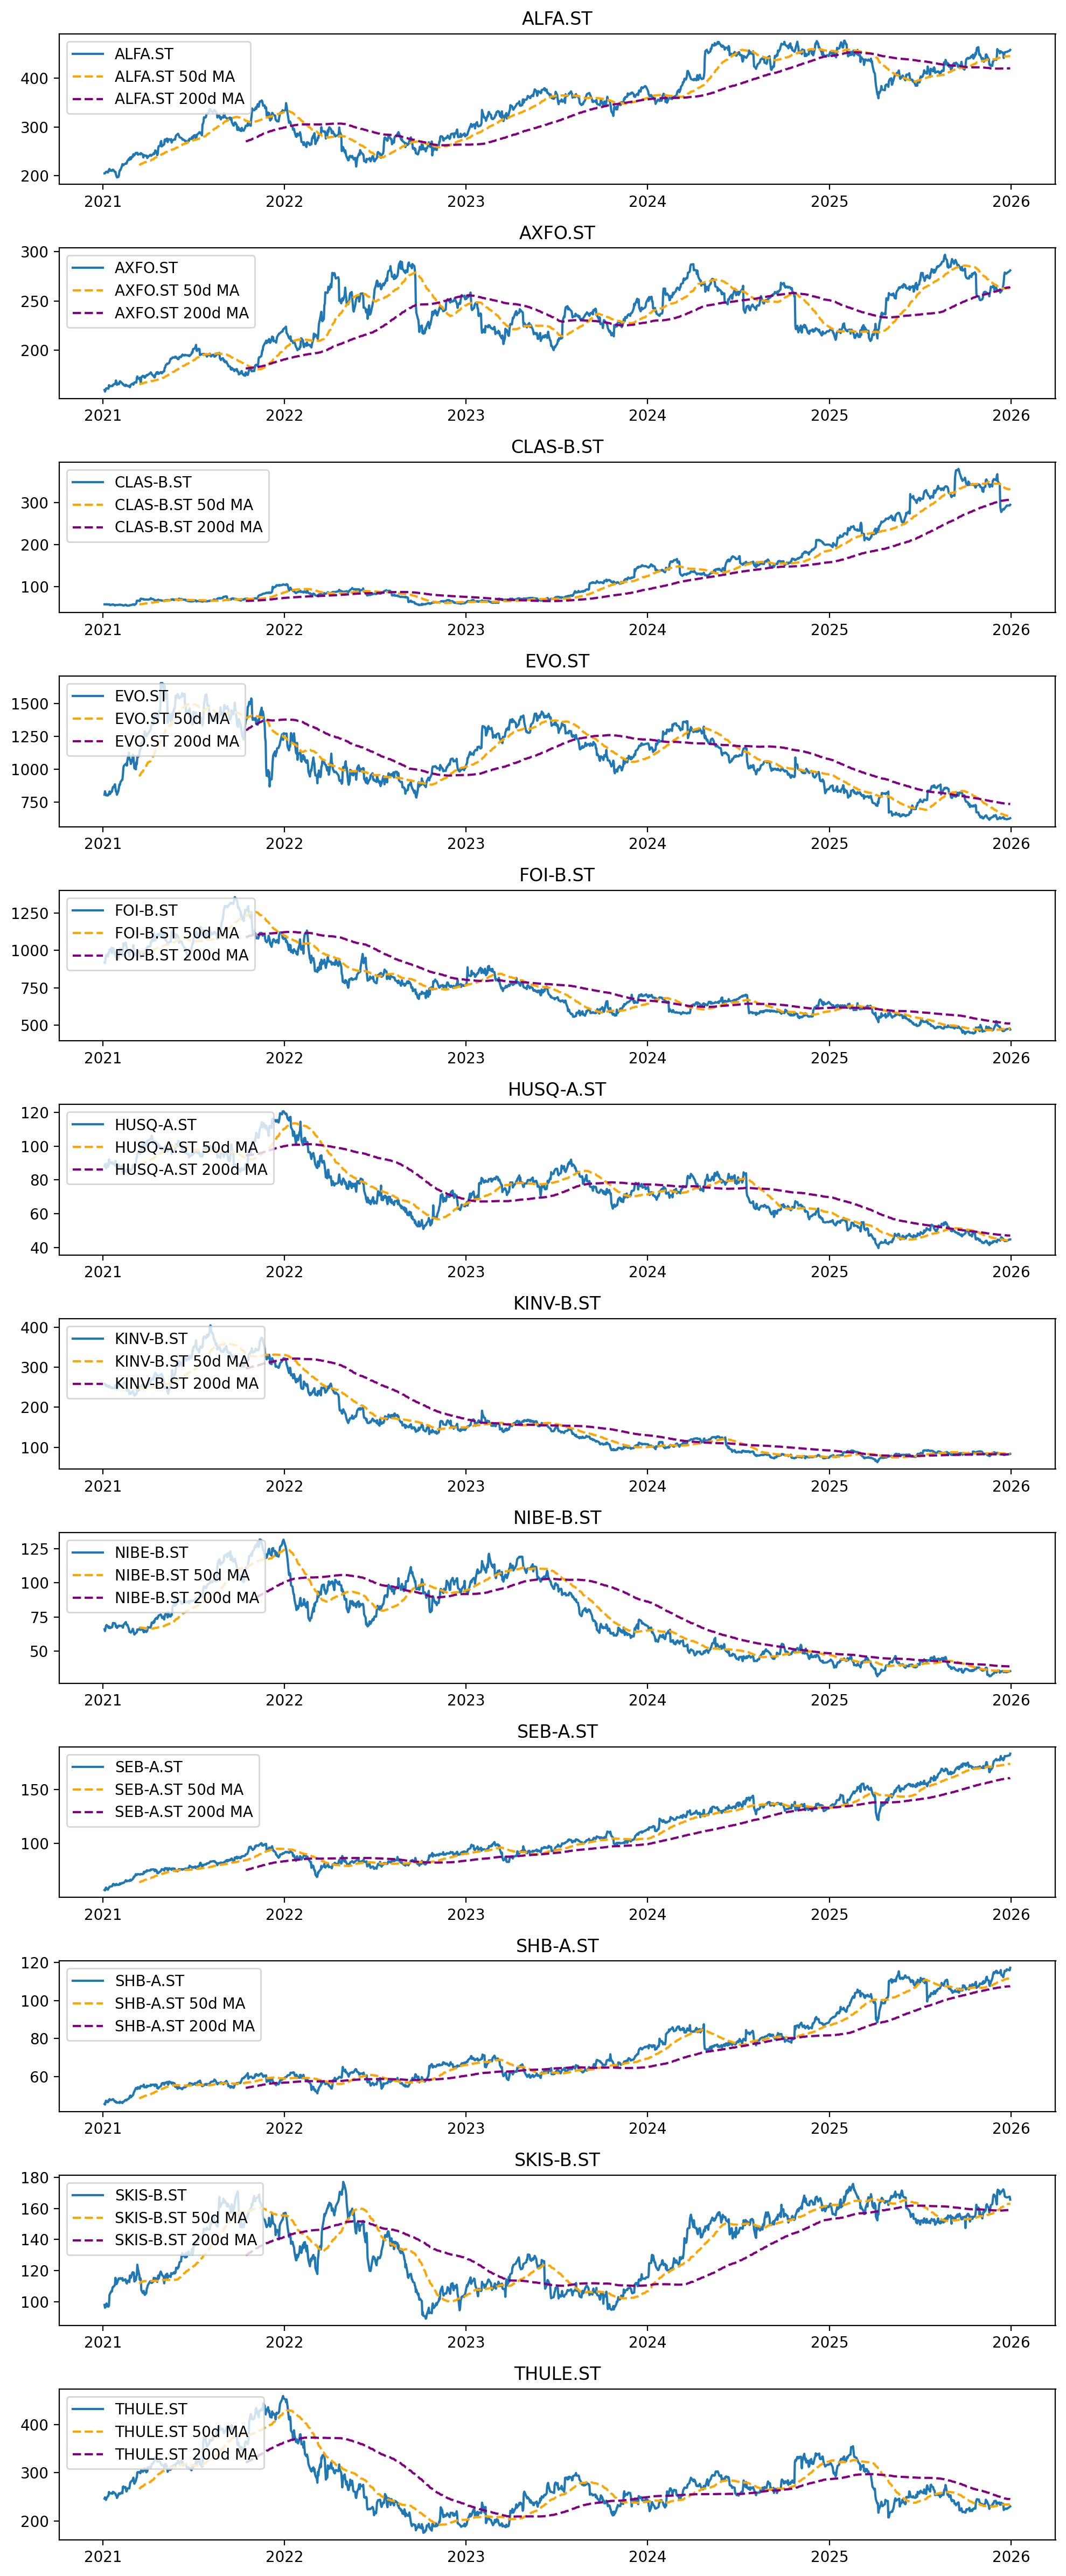

In [73]:
fig, axes = plt.subplots(len(data.columns), 1,              
                         figsize=(10, 2*len(data.columns)), 
                         sharex=False)                      

for ax, col in zip(axes, data.columns): 
    # Prisdata
    ax.plot(data.index, 
            data[col], 
            label=col)

    
    ax.plot(data.index, 
            data[col].rolling(window=50).mean(), 
            label=f'{col} 50d MA', 
            color="orange", 
            linestyle='--')

   
    ax.plot(data.index, 
            data[col].rolling(window=200).mean(), 
            label=f'{col} 200d MA', 
            color="purple", 
            linestyle='--')

    ax.set_title(col)
    ax.legend(loc=2)

plt.tight_layout() 
plt.show()

Kommentar aktier i protfölj: 

#### Visualisera portföljens korrelationsmatris (Spearman)

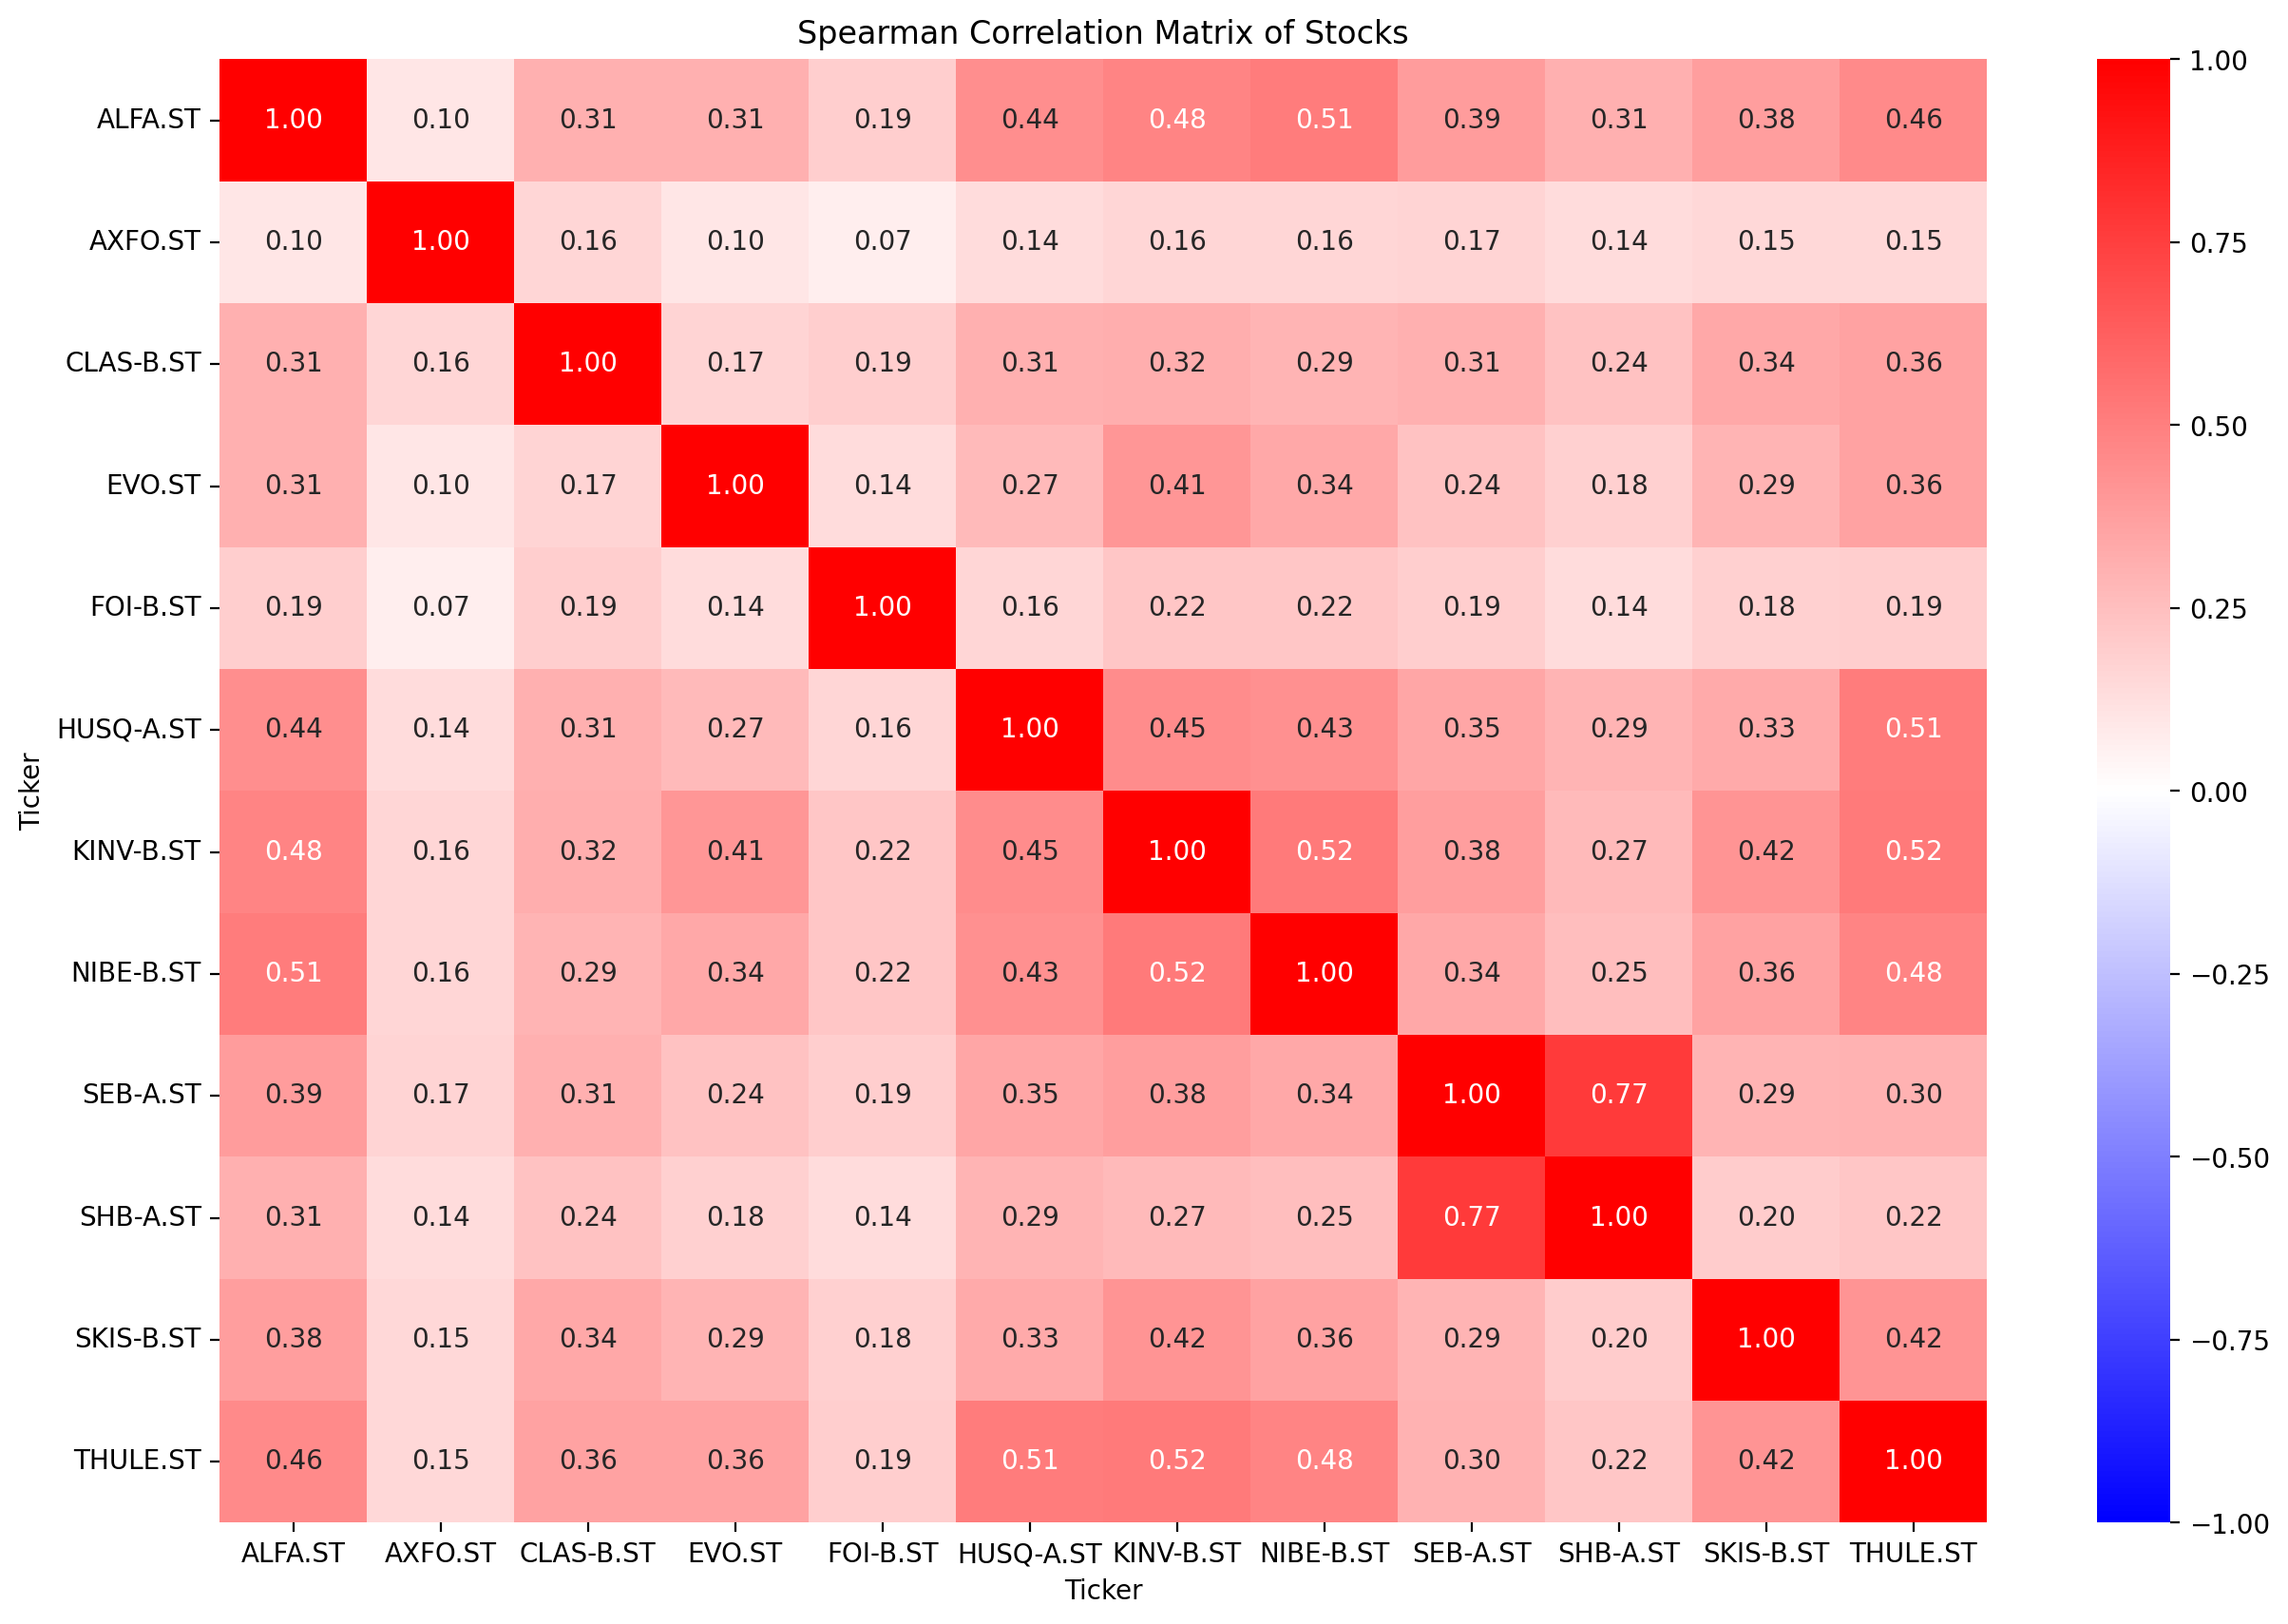

In [74]:
corr = returns.corr(method="spearman").round(2) # Samma som tidigare

plt.figure(figsize=(15, 10))

sns.heatmap(
    corr,             # Använd korrleationsmatrisen vi skapade ovan
    annot=True,       # Visa värden i varje ruta
    fmt=".2f",        # Visa två decimaler
    cmap="bwr",       # Blå–Vit–Röd färgskala
    vmin=-1, vmax=1,  # Färgskalan alltid mellan -1 och +1
    center=0,         # 0.0 = vit
    cbar=True         # Visa färgskala till höger
)

plt.title("Spearman Correlation Matrix of Stocks")
plt.show()

Kommentar korrelationsmatris: fixa så den blir vitare/blå

### 3.Portfölj optimering

In [75]:
port = rp.Portfolio(returns=returns)

# Calculating optimal portfolio

# Select method and estimate input parameters:
method_mu = 'hist' # Method to estimate expected returns based on historical data.
method_cov = 'hist' # Method to estimate covariance matrix based on historical data.
hist = True # Use historical scenarios for risk measures that depend on scenarios

model = 'Classic' # Could be Classic (historical), BL (Black Litterman) or FM (Factor Model)
rm = 'MV' # Risk measure used, could be 'MV': Standard Deviation, 'CVaR': Conditional Value at Risk, 'MDD': Maximum Drawdown of uncompounded cumulative returns (Calmar Ratio).
obj = 'Sharpe' # Objective function, could be Sharpe (Tangency Portfolio/Max Sharpe), MinRisk (Mean Variance Portfolio), MaxRet, or Utility
rf = 0.0 # Risk free rate
l = 0 # Risk aversion factor, only useful when obj is 'Utility'
port.short = False # Short-selling not allowed

# Optimize the portfolio with the constraints
# Set constraints:
#port.ainequality = A
#port.binequality = B    

# Estimate optimal portfolio:
port.assets_stats(method_mu=method_mu, method_cov=method_cov)
w = port.optimization(model=model, rm=rm, obj=obj, rf=rf, l=l, hist=hist)

#### Tolka portföljoptimering

In [76]:
summary = pd.DataFrame(index=returns.columns) 

# Årlig förväntad avkastning per aktie.
# port.mu antas vara periodens (daglig) förv. avkastning → multiplicera med 252 för att annualisera.
summary["E(return)"] = port.mu.T * 252

# Årlig standardavvikelse (volatilitet) per aktie.
# Diagonalen i kovariansmatrisen är variansen per aktie → sqrt = std (daglig) → *sqrt(252) för att annualisera.
# .loc[...] säkerställer att ordningen/namnen matchar returns-kolumnerna.
summary["std"] = np.sqrt(np.diag(port.cov.loc[summary.index, summary.index])) * np.sqrt(252)

# Kopierar aktiernas dagliga avkastningar och lägger till marknadsindexets dagliga avkastning som kolumn "MKT".
# Antag: benchmark_returns är redan pct_change() och tidsmässigt kompatibel med returns.
returns_mkt = returns.copy()
returns_mkt["mkt"] = benchmark_returns

# Variansen för marknadsindex (sample-varians, ddof=1).
var_m = returns_mkt["mkt"].var(ddof=1) #(sample-varians)

# Beta per aktie mot marknadsindex.
# Definition: beta_i = Cov(R_i, R_m) / Var(R_m)
# Vi använder pandas .cov() kolumnvis mot "MKT", och delar med indexets varians.
betas = returns_mkt.drop(columns="mkt").apply(lambda s: s.cov(returns_mkt["mkt"]) / var_m, axis=0)

# Lägger in Beta i sammanställningen.
summary["beta"] = betas

# Årlig marknadsavkastning (medel-daglig * 252) och vald riskfri ränta.
market_return = float(returns_mkt["mkt"].mean() * 252)
rf_rate = 0.02

# CAPM-avkastning per aktie: E[R_i] = r_f + beta_i * (E[R_m] - r_f)
summary["capm"] = rf_rate + summary["beta"]*(market_return-rf_rate)

# Vikter per aktie (antas matcha ordningen i summary.index).
summary["weight"] = w.round(4)


# Portföljens årliga förväntade avkastning = viktad summa av aktiernas årliga förv. avkastningar.
mu_p_annual = float((summary["weight"] * summary["E(return)"]).sum())

# Portföljens årliga standardavvikelse via kvadratisk form: sqrt(wᵀ Σ w) * sqrt(252).
sigma_p_annual = float(np.sqrt(summary["weight"].values @ (port.cov.values @ summary["weight"].values)) * np.sqrt(252))

# Portföljens beta = viktad summa av aktiernas betas.
portfolio_beta = float((summary["beta"] * summary["weight"]).sum())

# Portföljens CAPM (kan också räknas direkt med portfolio_beta): r_f + beta_p*(E[R_m]-r_f).
capm_mu_p_annual = rf_rate + portfolio_beta * (market_return - rf_rate)

# Lägger till en rad för hela portföljen med E(Return), STD, Beta, CAPM och total vikt (1.0 om vikter summerar till 1).
summary.loc["Portfolio"] = [mu_p_annual, sigma_p_annual, portfolio_beta, capm_mu_p_annual, float(summary["weight"].sum())]

display(summary)


,E(return),std,beta,capm,weight
Ticker,,,,,
ALFA.ST,0.196104,0.263278,1.099824,0.105552,0.1153
AXFO.ST,0.137719,0.220249,0.226095,0.037587,0.1990
CLAS-B.ST,0.391503,0.363335,0.693704,0.073961,0.2487
EVO.ST,0.035076,0.410561,1.135364,0.108317,0.0000
FOI-B.ST,-0.078531,0.333167,0.515869,0.060128,0.0000
HUSQ-A.ST,-0.072162,0.356522,1.169264,0.110954,0.0000
KINV-B.ST,-0.146803,0.399290,1.495161,0.136305,0.0000
NIBE-B.ST,-0.039657,0.412859,1.447231,0.132576,0.0000
SEB-A.ST,0.260715,0.228372,0.948014,0.093743,0.3016


In [77]:
r_p = float(summary.loc["Portfolio", "E(return)"])
std_p = float(summary.loc["Portfolio", "std"])

sharpe = float(np.round((r_p-rf_rate)/std_p, 4))
sharpe

1.3846

Kommentar sammanställning:
* Kommentar 1
* Kommentar 2
* Kommentar ....

In [78]:
# Tabellen nedan visar de olika aktierna i förhållande till sina klassificeringar (som du definierade i Excel-filen), samt deras vikt i portföljen
w_classes = pd.concat([asset_classes.set_index('Assets'), w], axis=1).round(4)

display(w_classes)

,Class 1,Class 2,weights
ALFA.ST,Industrials,Låg risk,0.1153
AXFO.ST,Consumer Defensive,Låg risk,0.1990
CLAS-B.ST,Consumer Cyclical,Medel risk,0.2487
EVO.ST,Consumer Cyclical,Låg risk,0.0000
FOI-B.ST,Consumer Cyclical,Låg risk,0.0000
HUSQ-A.ST,Industrials,Hög risk,0.0000
KINV-B.ST,Financial Services,Hög risk,0.0000
NIBE-B.ST,Industrials,Medel risk,0.0000
SEB-A.ST,Financial Services,Låg risk,0.3016
SHB-A.ST,Financial Services,Låg risk,0.1355


In [79]:
w_class1 = w_classes[["Class 1", "weights"]].groupby(['Class 1']).sum().round(4)
display(w_class1)

,weights
Class 1,
Consumer Cyclical,0.2487
Consumer Defensive,0.1990
Financial Services,0.4371
Industrials,0.1153


In [80]:
display(w_classes[w_classes['Class 2'].str.contains('Hög risk', na=False)])

,Class 1,Class 2,weights
HUSQ-A.ST,Industrials,Hög risk,0.0
KINV-B.ST,Financial Services,Hög risk,0.0


In [81]:
# I denna cell grupperar vi aktiernas vikt i relation till deras klass, i detta fall Class 2 Risknivå
w_class2 = w_classes[["Class 2", "weights"]].groupby(['Class 2']).sum().round(4)
display(w_class2)

,weights
Class 2,
Hög risk,0.0000
Låg risk,0.7514
Medel risk,0.2487


#### Visualisera portföljoptimering

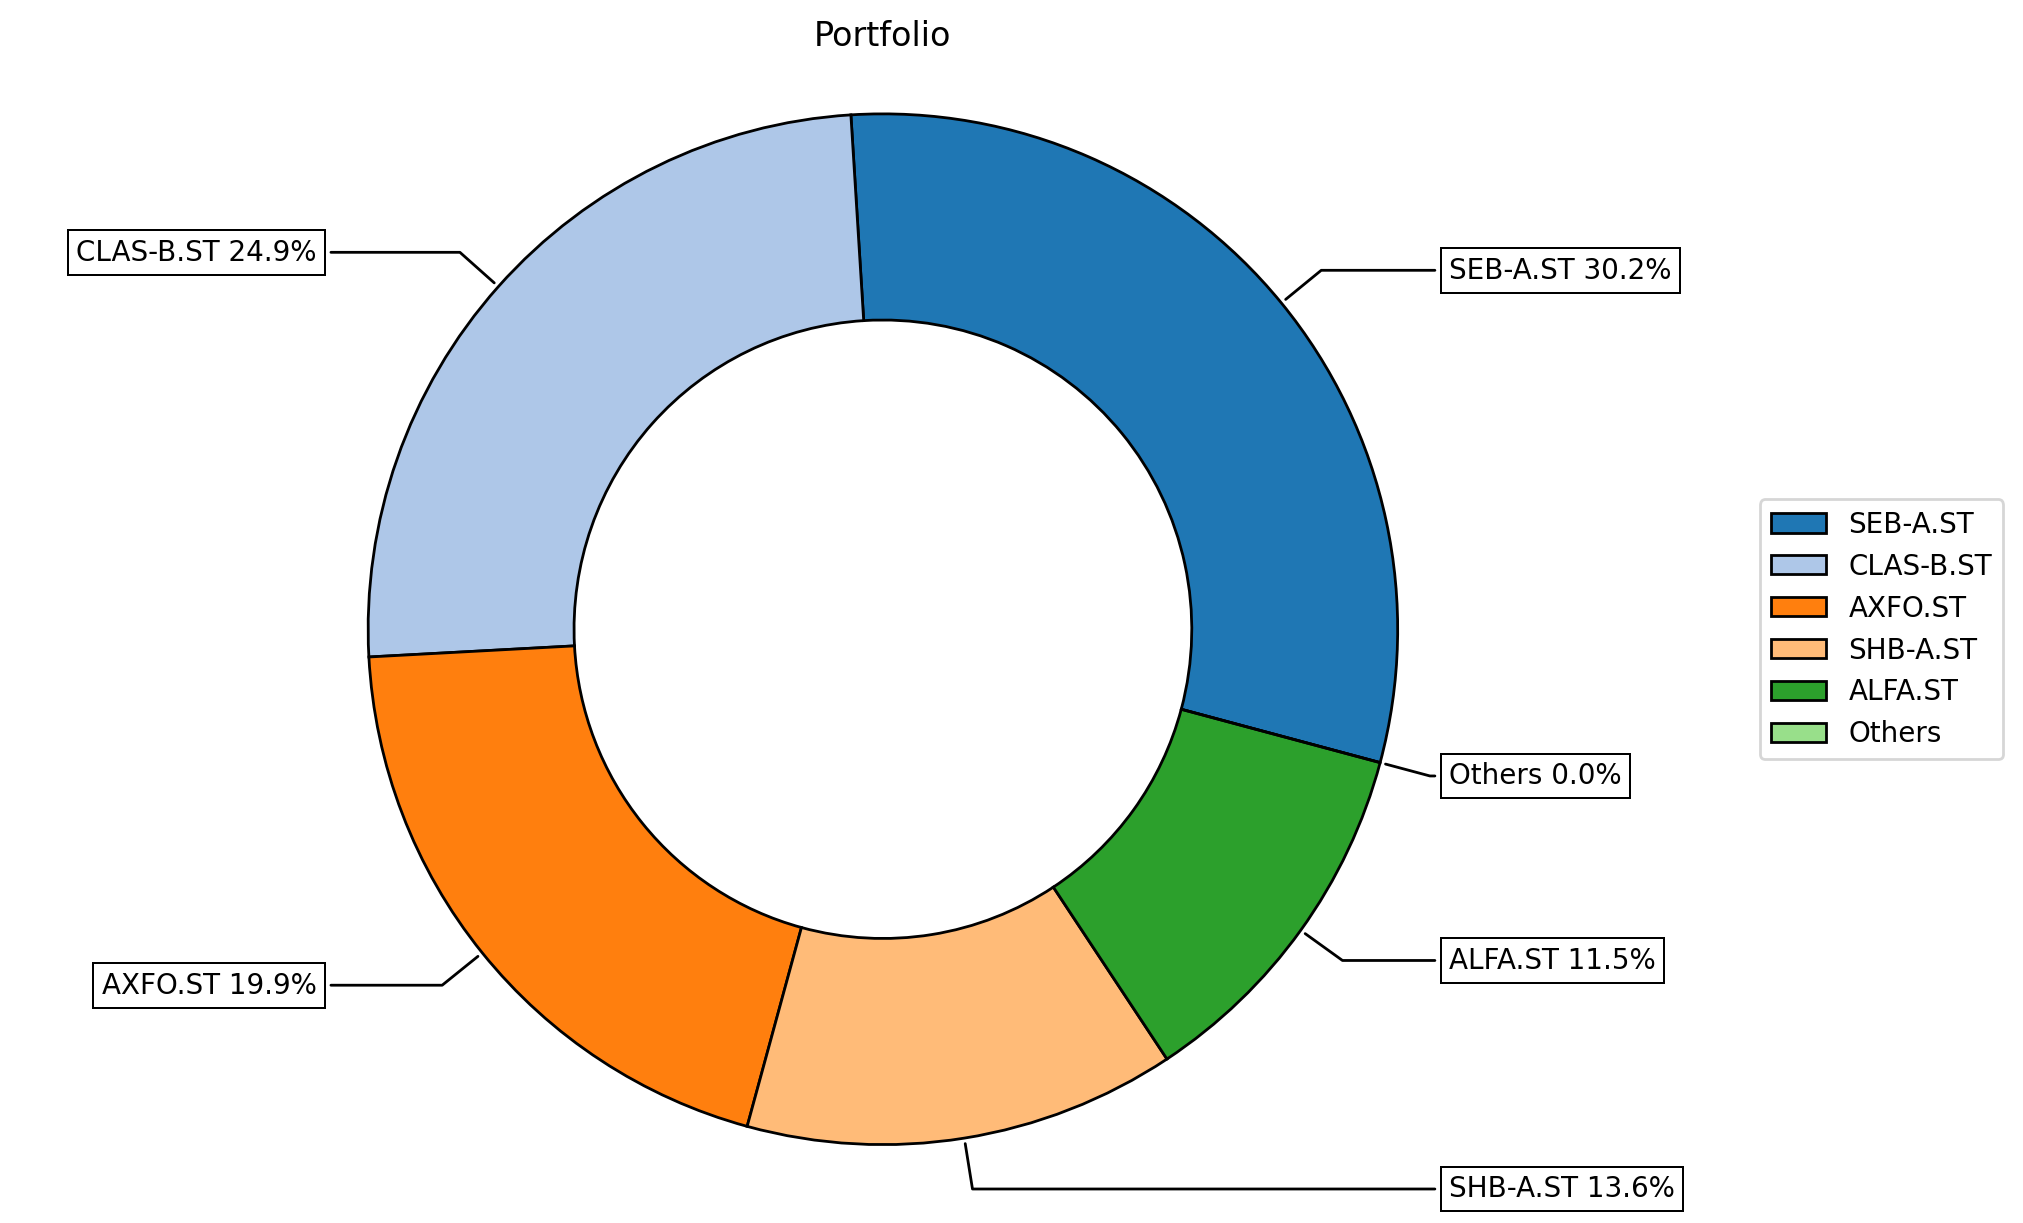

In [82]:
ax = rp.plot_pie(w=w, title="Portfolio", others=0.05, nrow=25, 
                 cmap='tab20', height=6, width=10, ax=None)
plt.show()

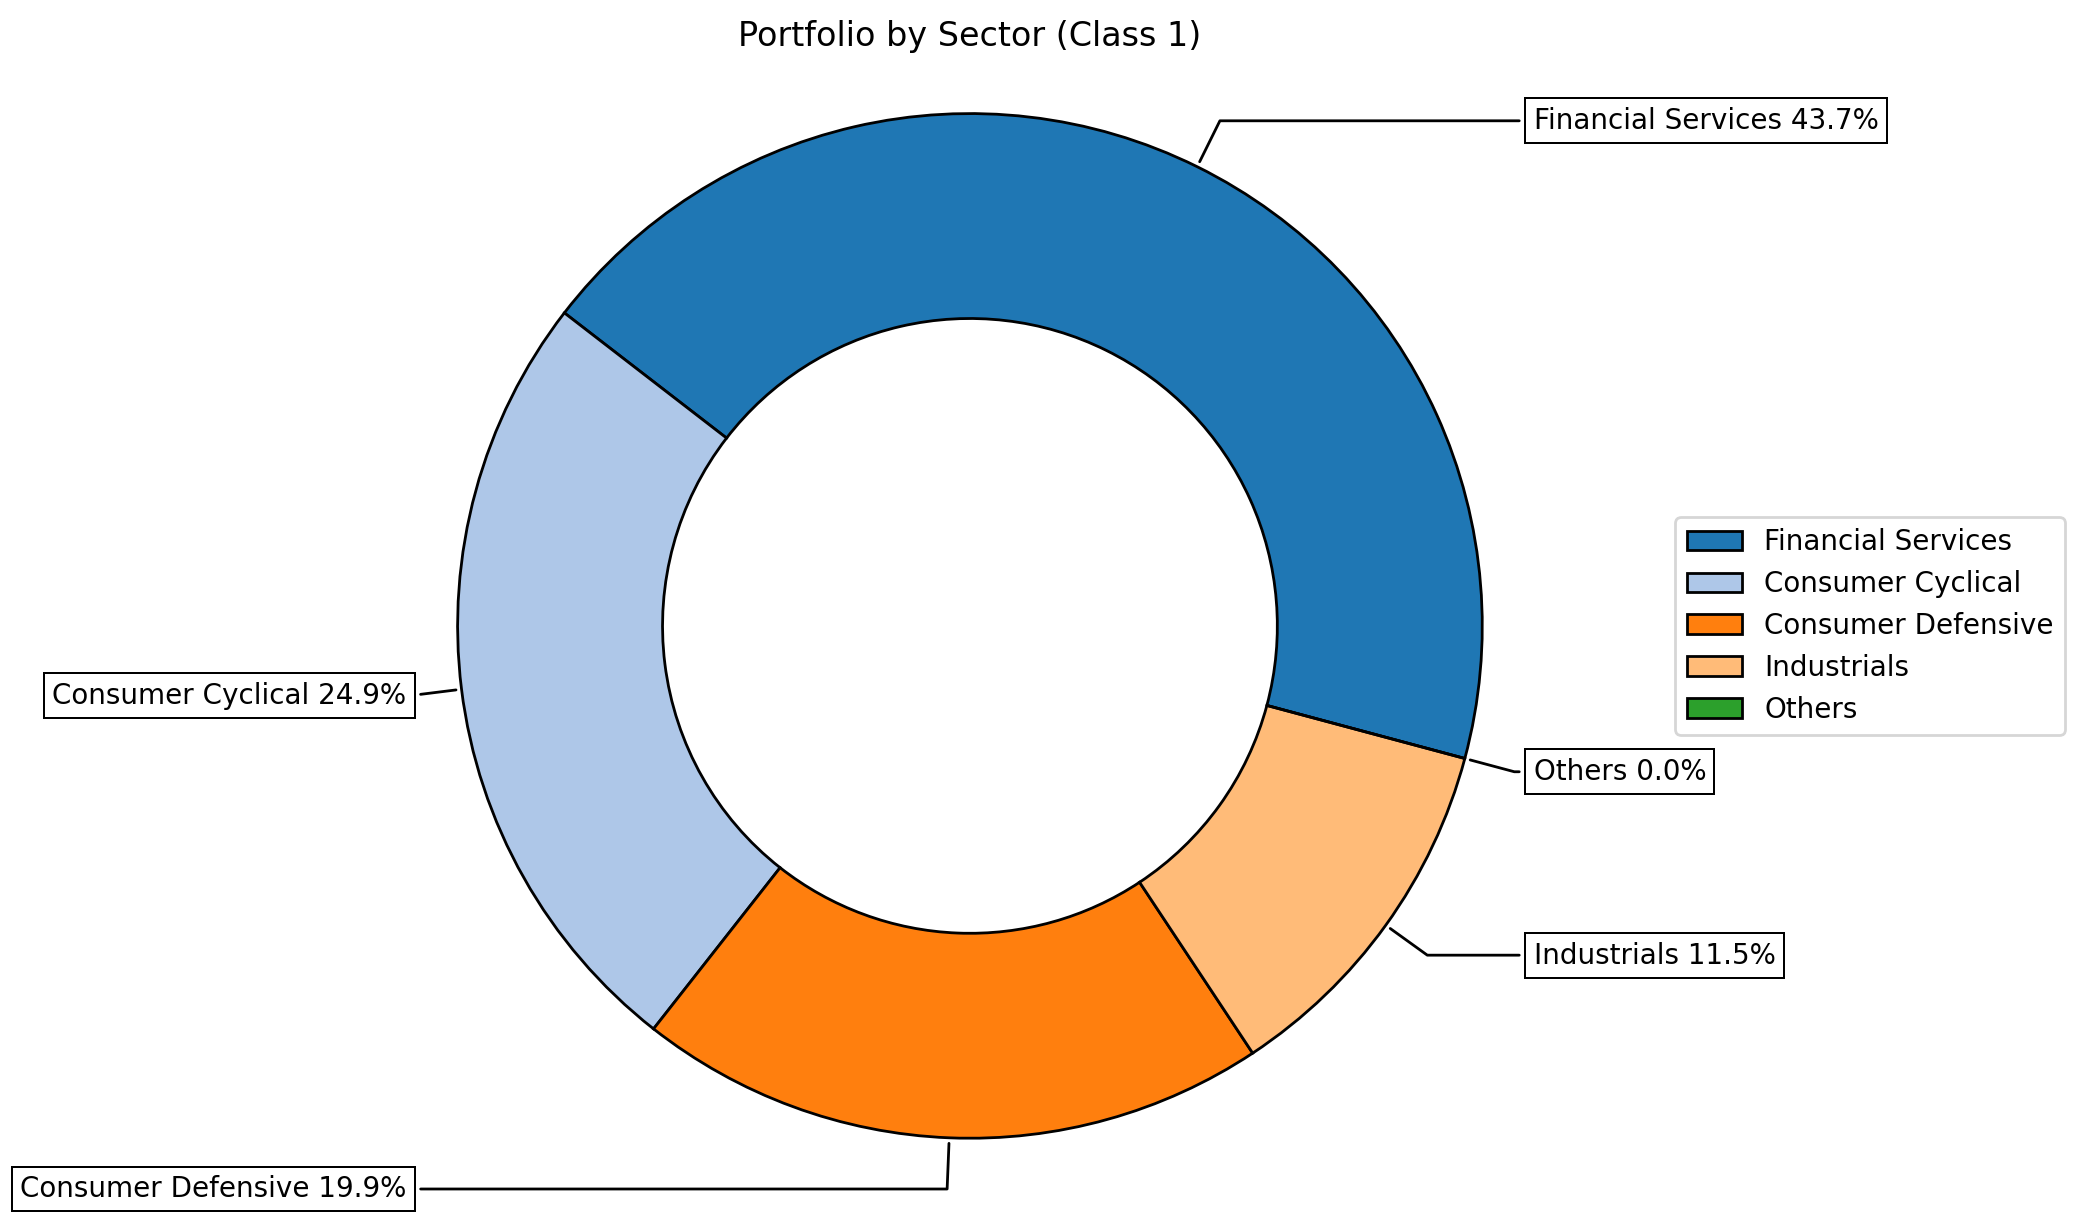

In [83]:
ax = rp.plot_pie(w=w_class1, title="Portfolio by Sector (Class 1)", others=0.05, nrow=25, 
                 cmap='tab20', height=6, width=10, ax=None)
plt.show()

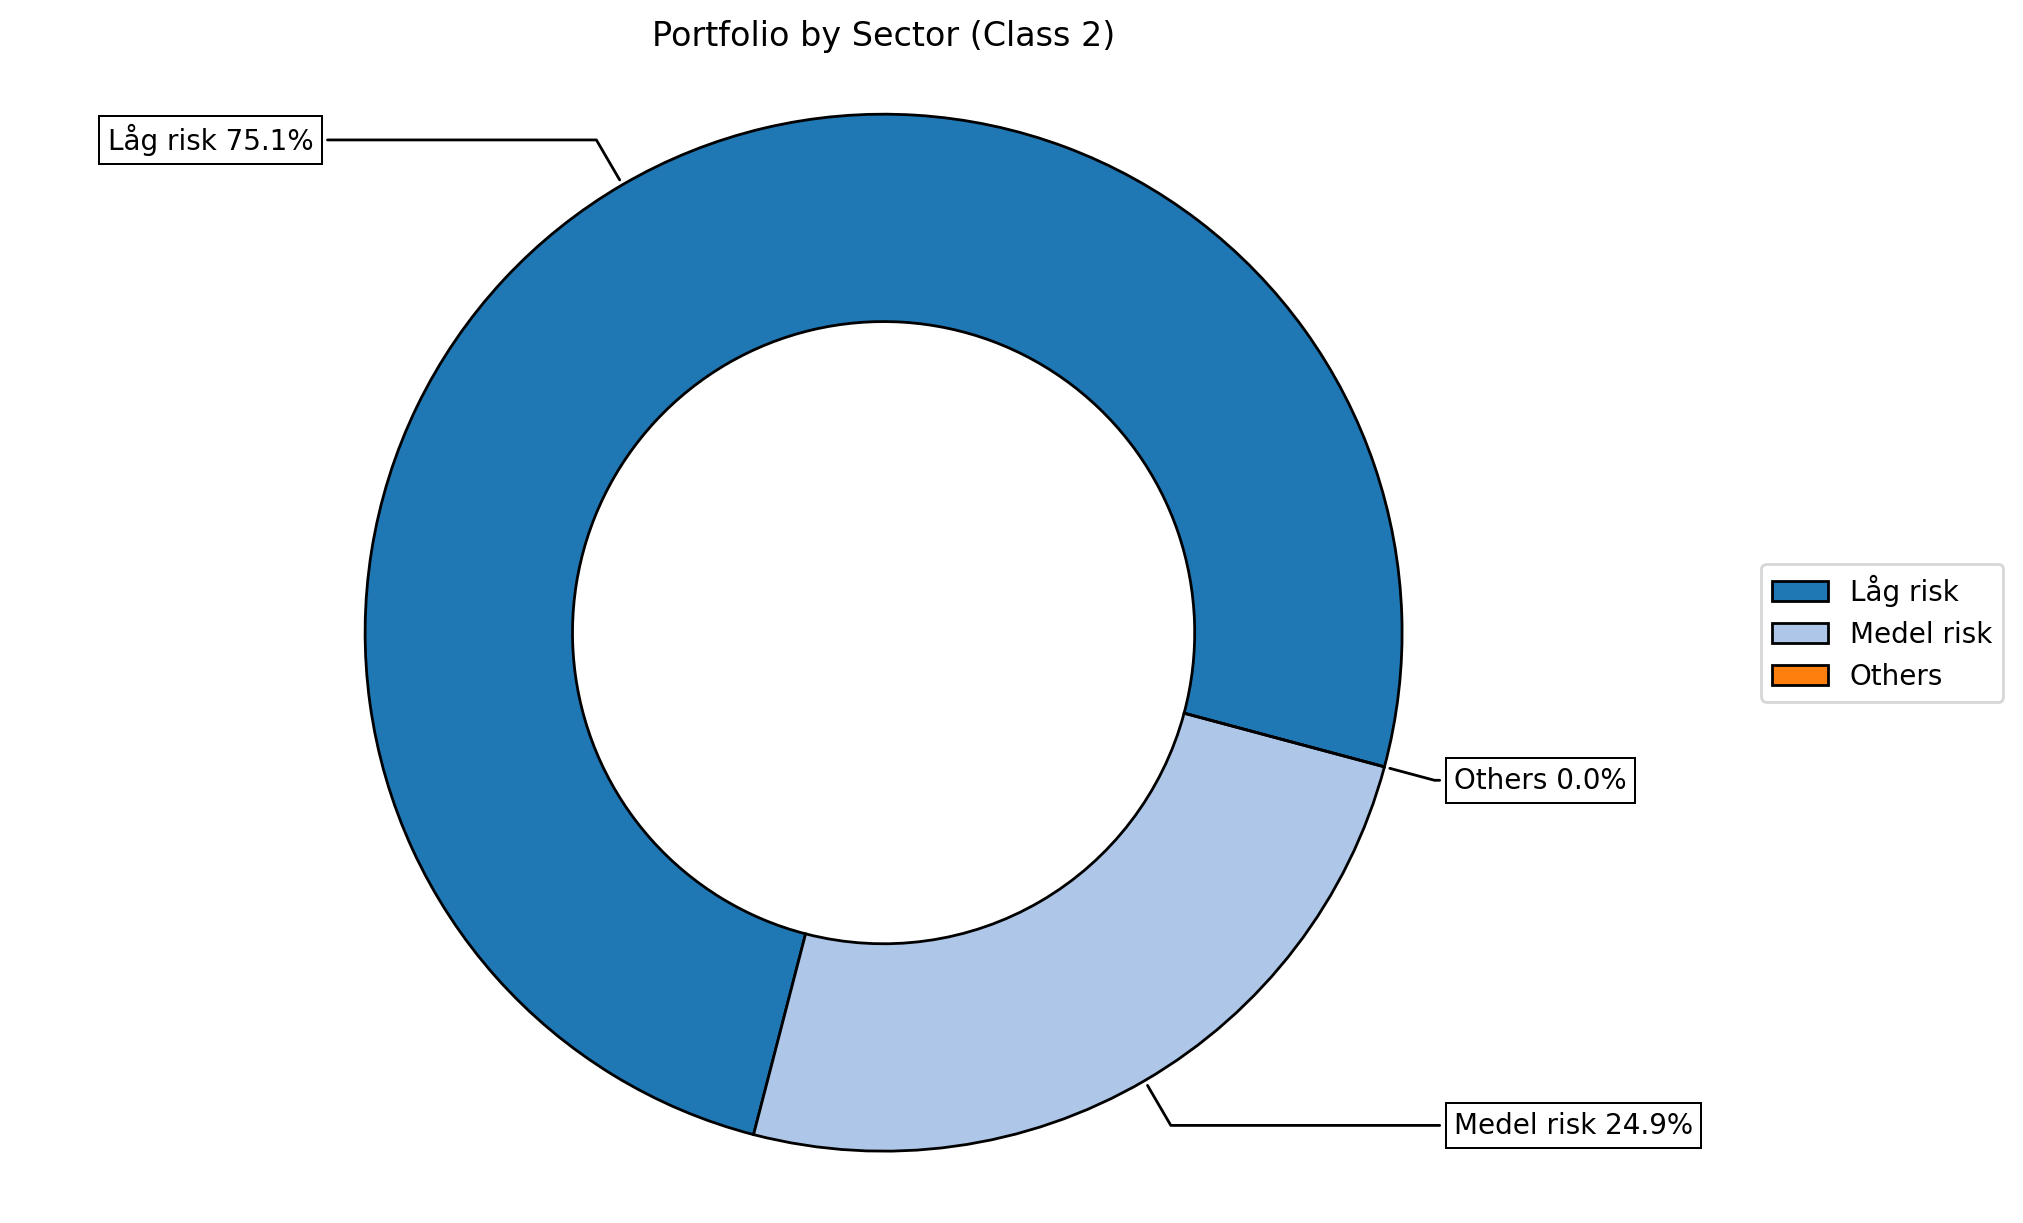

In [84]:
# Denna kod visualiserar aktiernas vikter i din portfölj som ett cirkeldiagram

ax = rp.plot_pie(w=w_class2, title="Portfolio by Sector (Class 2)", others=0.05, nrow=25, 
                 cmap='tab20', height=6, width=10, ax=None)
plt.show()

#### Visualisera Effektiva fronten

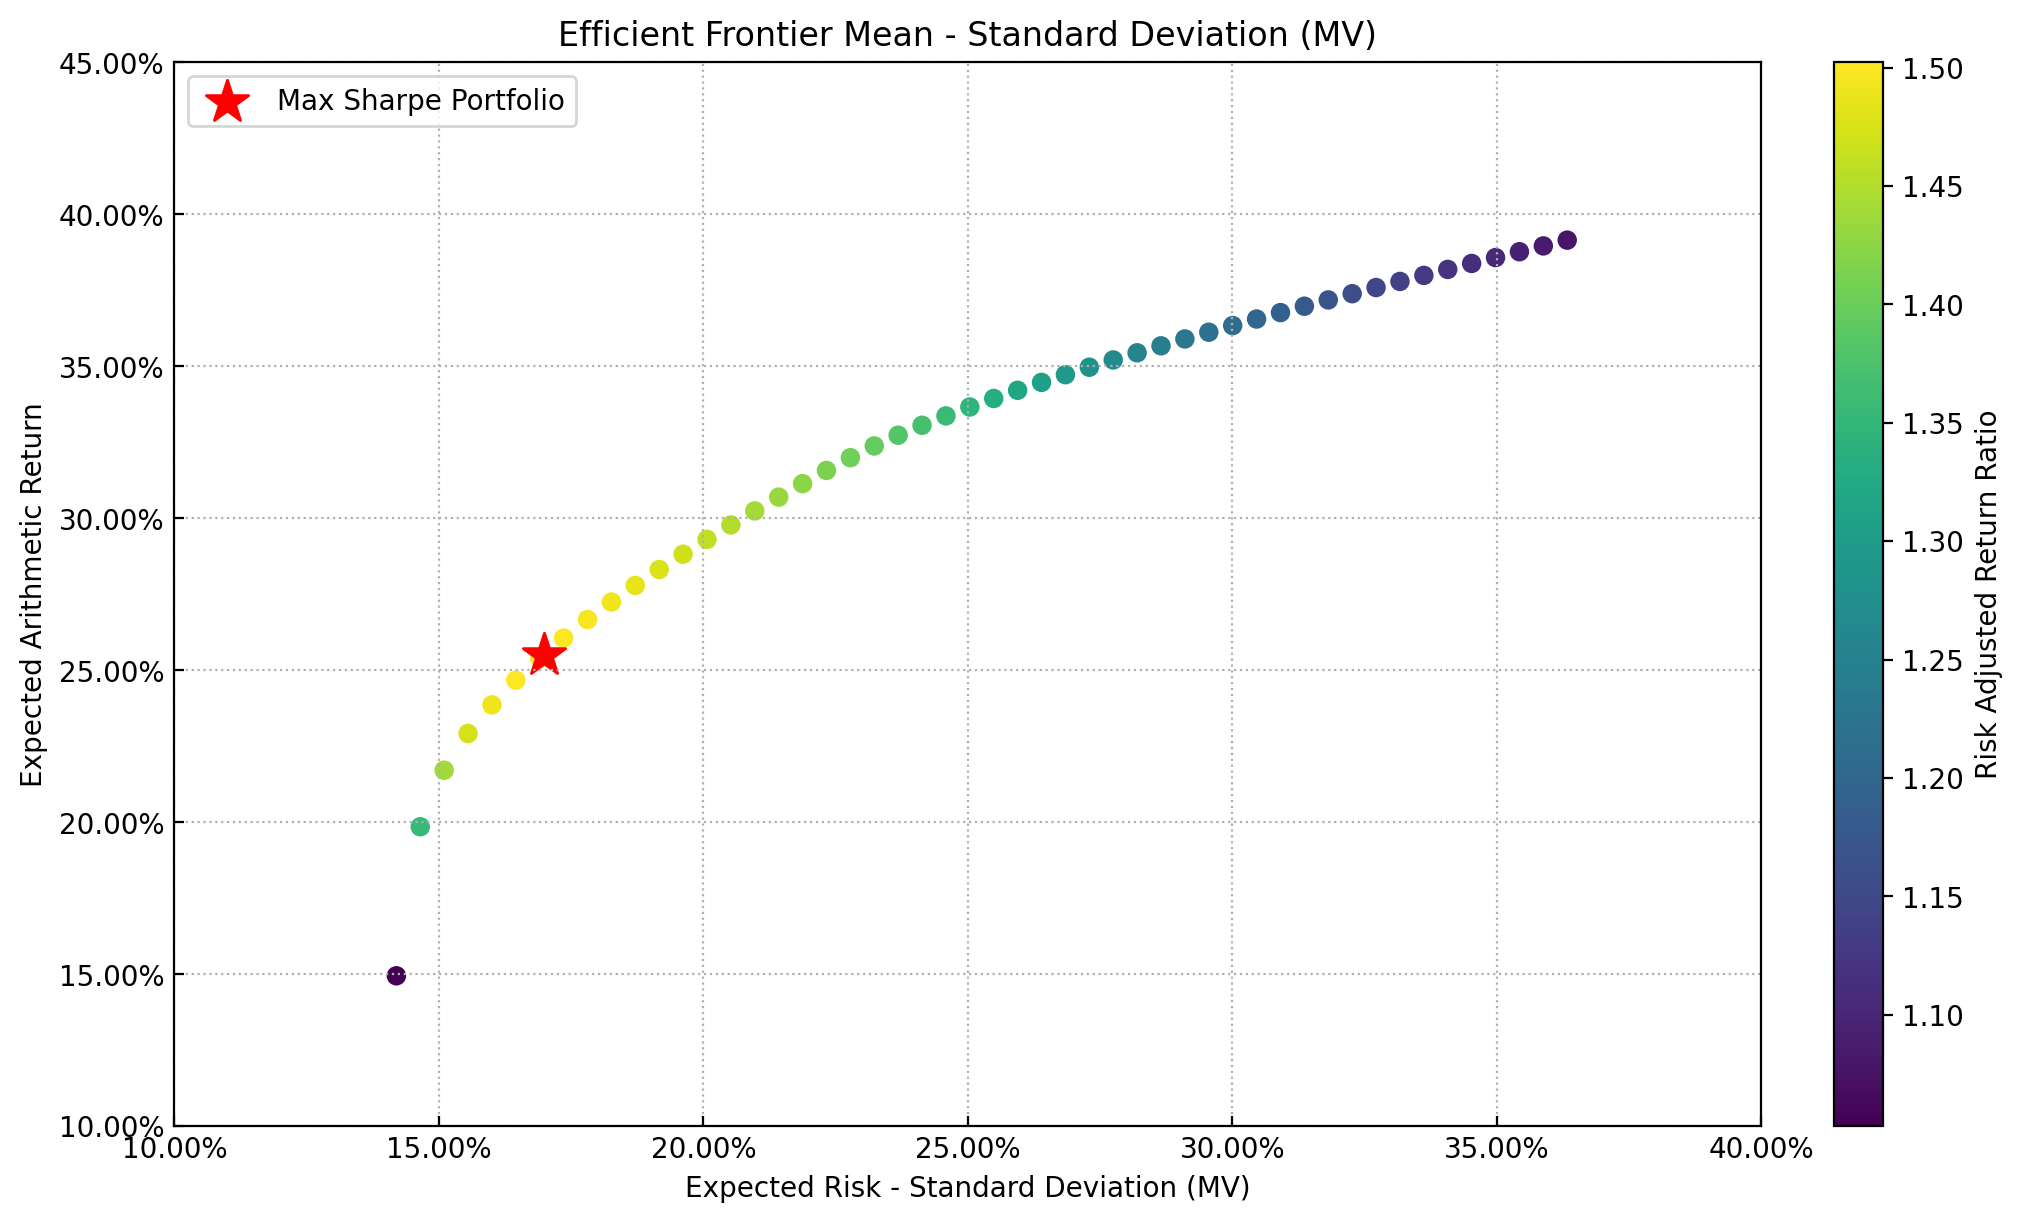

In [85]:
# Koden nedan är till för att visualisera the Efficient Frontier

label = 'Max Sharpe Portfolio' # Titel
mu = port.mu # Förväntad avkastning
cov = port.cov # Covariansmatris
returns = port.returns # Aktiernas avkastning
points = 50 # Antal punkter på Efficient Frontier

frontier = port.efficient_frontier(model=model, rm=rm, points=points, rf=rf, hist=hist)

ax = rp.plot_frontier(w_frontier=frontier, mu=mu, cov=cov, returns=returns, rm=rm,
                      rf=rf, alpha=0.05, cmap='viridis', w=w, label=label,
                      marker='*', s=16, c='red', height=6, width=10, ax=None)

plt.show()

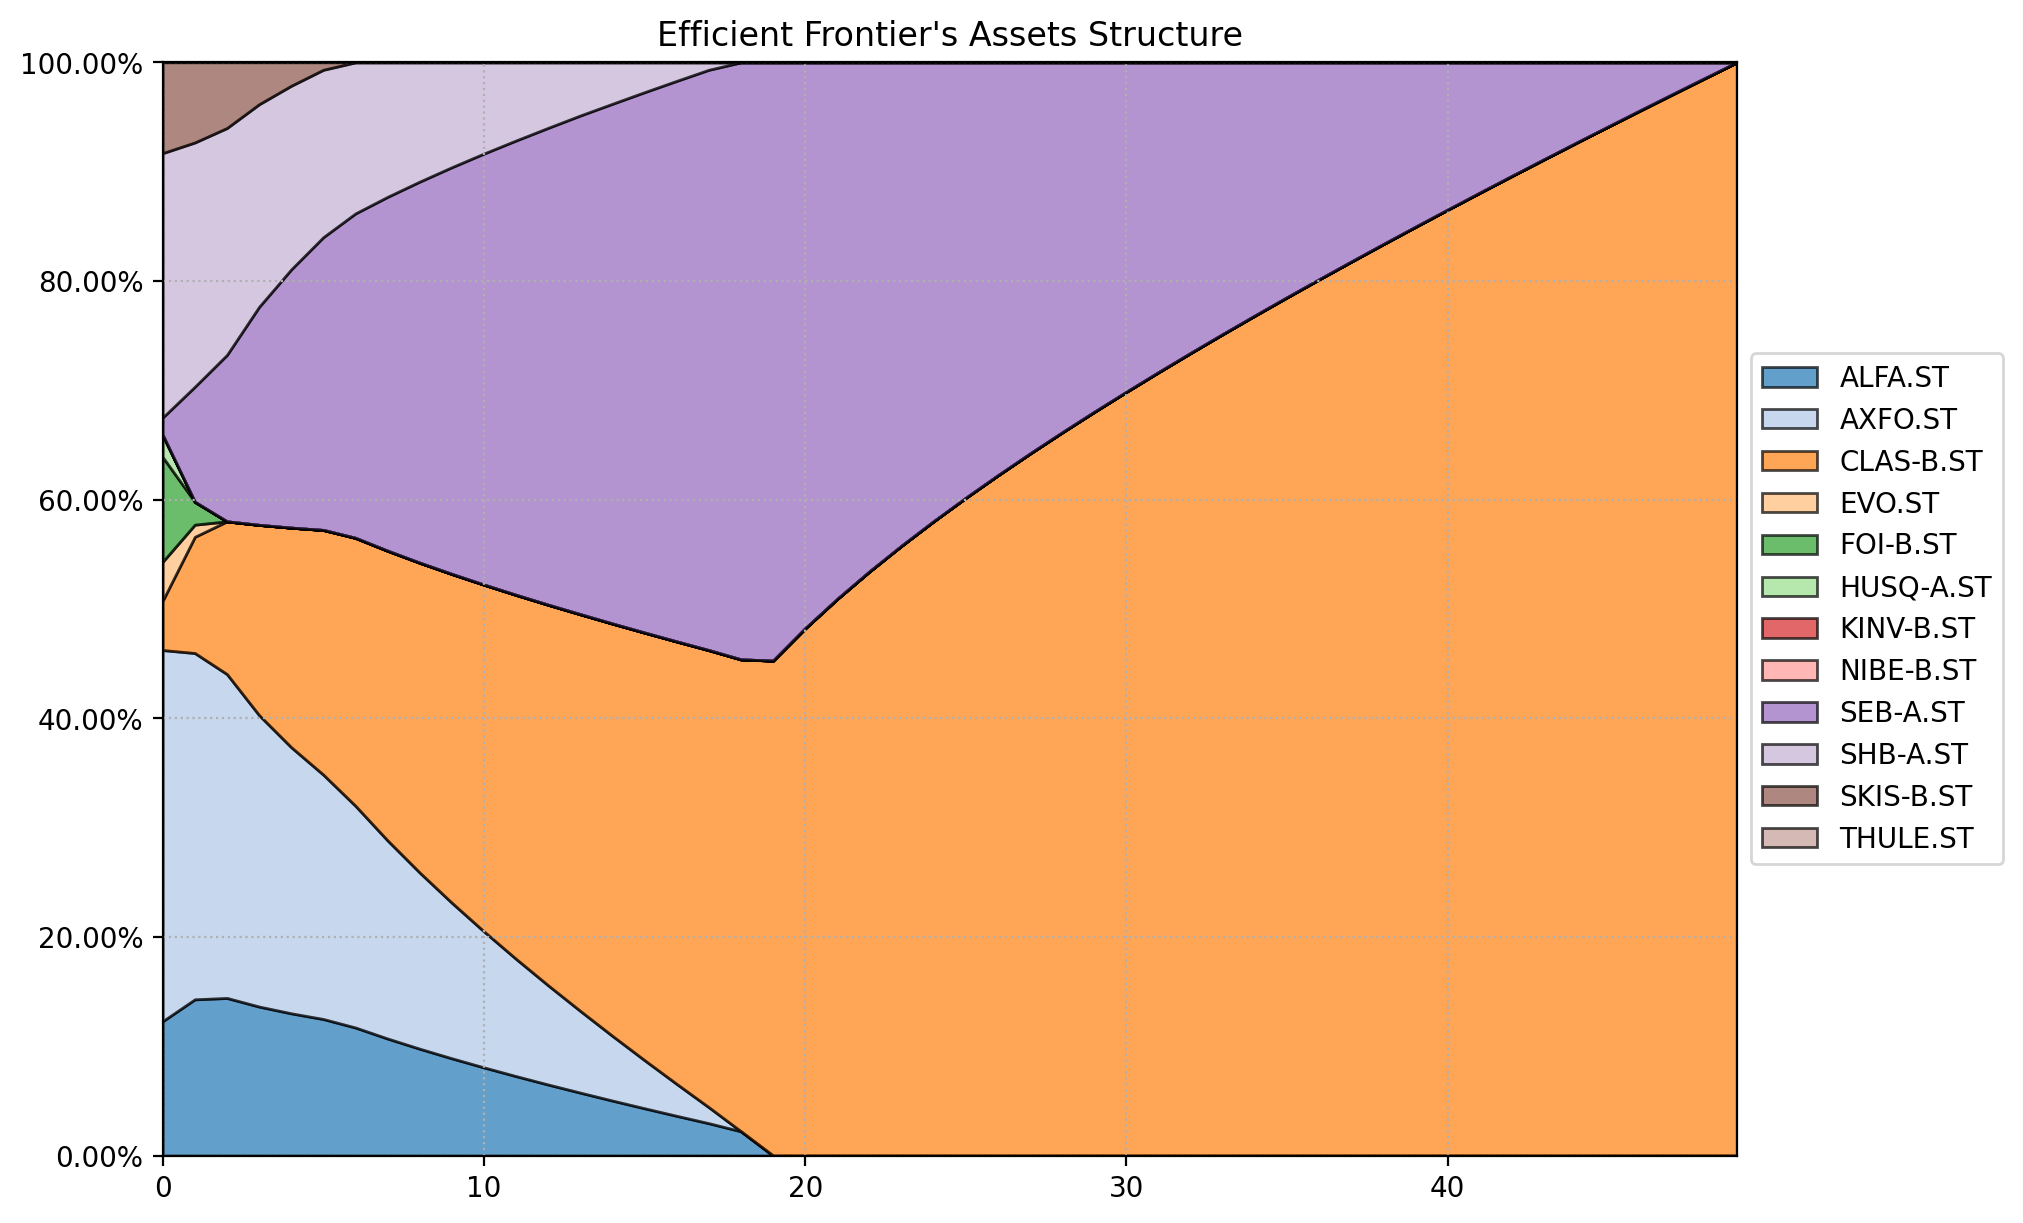

In [86]:
ax = rp.plot_frontier_area(w_frontier=frontier, cmap="tab20", height=6, width=10, ax=None)
plt.show()

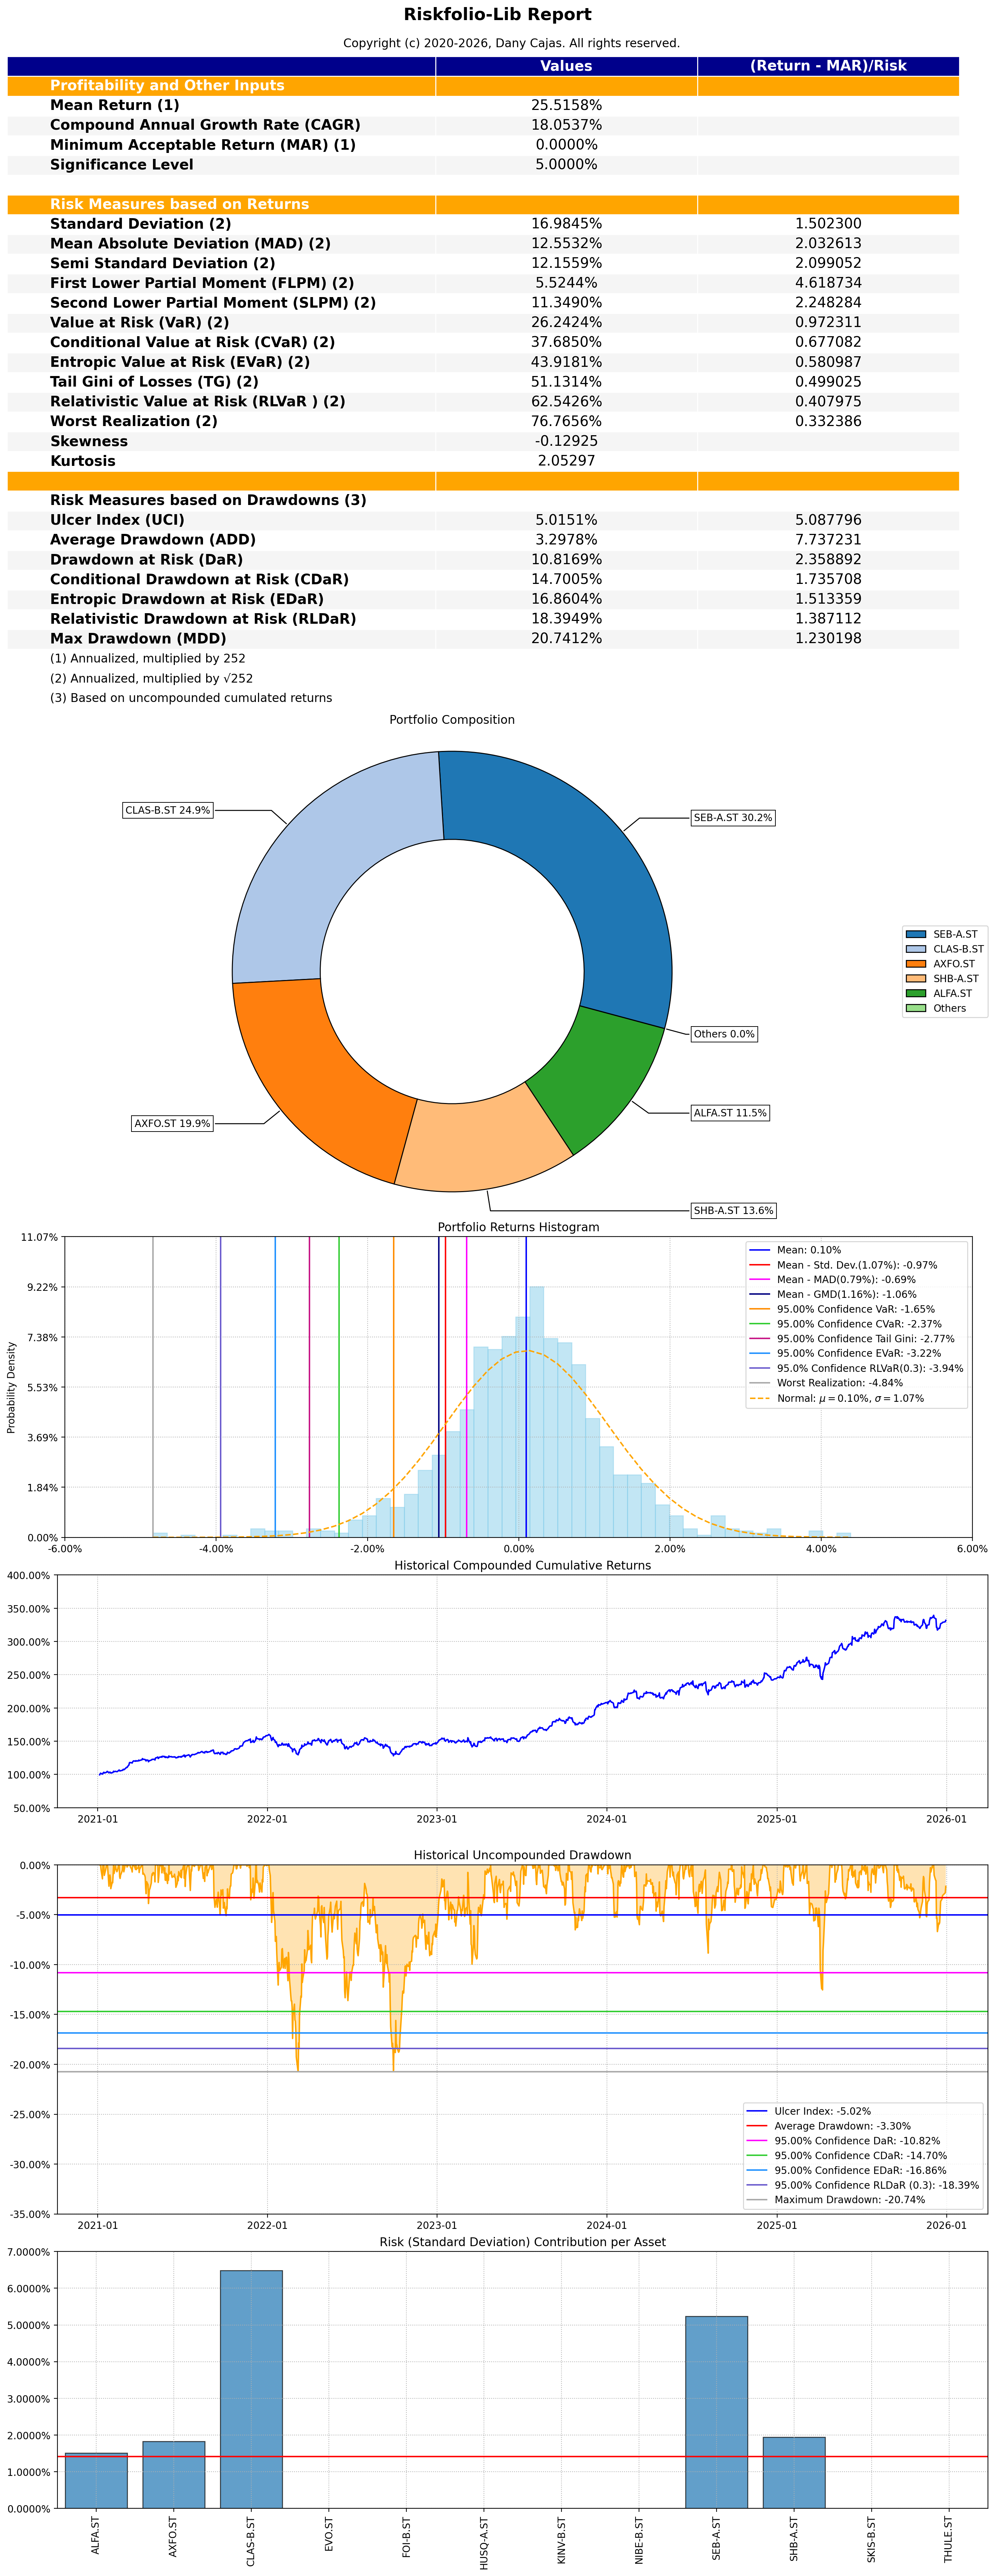

In [87]:
ax = rp.jupyter_report(returns,
                       w,
                       rm=rm,
                       rf=0,
                       alpha=0.05, # alpha=0.05 motsvarar 95% konfidens för VaR/CVaR
                       height=6,
                       width=14,
                       others=0.05,
                       nrow=25,
                       t_factor=252) # Rapporten antar daglig data och annualiserar med 252 handelsdagar

plt.show()

In [ ]:
with pd.ExcelWriter("export_portfolio_A.xlsx", engine="xlsxwriter", mode="w") as writer:
    summary.to_excel(writer, sheet_name="Summary", index=True)
    w_classes.to_excel(writer, sheet_name="Classes", index=True)
    w_class1.to_excel(writer, sheet_name="Class 1", index=True)
    w_class2.to_excel(writer, sheet_name="Class 2", index=True)
